# FIREBRIDGE: understand your data before harmonizing it

This notebook explores the actual downloaded observations. It uses the full archive profiles and small regional Parquet tables produced by `analysis/profile_archives.py`. Original ZIPs are unchanged.

**Questions:** What does a row represent? Which sensors, years and locations do we have? Which fields are comparable? What quality issues exist? Can the supplied data support the blueprint's experiment?

Read `reports/FIREBRIDGE_EDA.md` for the narrative and `reports/DATA_ACCESS.md` for acquisition status. No model is fitted. Detection absence is never labeled as an observed negative.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
TABLES = ROOT / 'reports/tables'
DATA = ROOT / 'data/processed'
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 70)
profiles = json.loads((TABLES/'archive_profiles.json').read_text())
pilot = pd.read_parquet(DATA/'pilot_detections.parquet')
regional = pd.read_parquet(DATA/'regional_detections.parquet')
print(f'{len(profiles)} archives; {sum(p["rows"] for p in profiles):,} global rows scanned')
print(f'{len(pilot):,} valid deduplicated pilot detections; {len(regional):,} regional detections')


10 archives; 148,475,929 global rows scanned
2,923 valid deduplicated pilot detections; 34,744 regional detections


## 1. Inventory and source identity

One row is a **detected thermal-anomaly pixel at acquisition time**. It is not necessarily one fire. Different resolution, time, confidence, and processing create different counts.

`M-C61` = MODIS Collection 6.1 (Aqua + Terra). `SV-C2` = VIIRS S-NPP. `J1V-C2` = NOAA-20. `J2V-C2` = NOAA-21. `LS` = Landsat. Filename suffixes are request IDs, not years. Use the actual date columns.

In [2]:
display(pd.read_csv(TABLES/'inventory.csv'))
display(pd.read_json(TABLES/'extracted_copies.json'))

,archive,stream,platforms,first_date,last_date,rows,pilot_rows,south_spain_rows,compressed_MB,uncompressed_MB,duplicate_hash_excess
0,DL_FIRE_J1V-C2_42006.zip,standard,N20,2023-01-01,2024-01-01,21424849,646,1801,384.170041,1734.297116,0
1,DL_FIRE_J1V-C2_42011.zip,standard,N20,2024-01-01,2025-01-01,22663860,332,2226,406.201276,1833.242288,0
2,DL_FIRE_J1V-C2_42016.zip,standard,N20,2025-01-01,2026-01-01,18503973,418,2596,334.326979,1494.912910,0
3,DL_FIRE_J2V-C2_42012.zip,NRT,N21,2024-01-01,2025-01-01,21564042,322,2212,386.434003,1809.655231,0
4,DL_FIRE_J2V-C2_42017.zip,NRT,N21,2025-01-01,2026-01-01,17701888,387,2540,319.585747,1483.713170,0
5,DL_FIRE_LS_42010.zip,NRT,"L9,L8",2024-01-01,2025-01-01,1581063,0,0,16.699042,93.756892,304
6,DL_FIRE_LS_42015.zip,NRT,"L9,L8",2025-01-01,2026-01-01,1654208,0,0,16.752245,98.159221,0
7,DL_FIRE_M-C61_42014.zip,standard,"Aqua,Terra",2025-01-01,2026-01-01,3715075,110,615,66.225141,295.723960,0
8,DL_FIRE_SV-C2_42013.zip,standard,SNPP,2024-01-01,2025-01-01,21122764,305,1763,377.448465,1707.548051,0
9,DL_FIRE_SV-C2_42018.zip,standard,SNPP,2025-01-01,2026-01-01,18544207,405,2464,333.679008,1497.774689,0


,path,bytes,crc32,matching_archives,ingested
0,/home/da-rog/Downloads/nasa hackathon data/DL_FIRE_LS_42015/fire_n...,98159221,fb74cdf0,[DL_FIRE_LS_42015.zip],False


## 2. Schema, units, missing values and outliers

Read the field dictionary before merging columns. MODIS confidence is numeric; VIIRS confidence is categorical. Landsat scan/track do not mean kilometers. NRT lacks fields found in the standard files. Missing FRP is not zero FRP.

In [3]:
display(pilot.head(8))
display(pilot.dtypes.to_frame('derived_dtype'))
quality = pd.read_csv(TABLES/'quality_checks.csv')
display(quality[quality.rows > 0])
display(pd.read_csv(TABLES/'global_numeric_profile.csv'))

,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,...,stream,acq_utc,sensor_family,confidence_class,retained,year,month,solar_hour,x_m,y_m,grid_x_5km,grid_y_5km,pilot,southern_spain_rectangle,morocco_context_rectangle
0,35.17056,-6.05516,315.73,0.51,0.41,2025-01-01,0153,N20,VIIRS,n,2,275.27,1.74,N,0,...,standard,2025-01-01 01:53:00+00:00,VIIRS,nominal,True,2025,1,1.479656,-584239.864724,4.216558e+06,-117,843,True,False,True
1,35.76291,-5.42276,299.69,0.57,0.52,2025-01-02,0134,N20,VIIRS,n,2,280.62,0.97,N,0,...,standard,2025-01-02 01:34:00+00:00,VIIRS,nominal,True,2025,1,1.205149,-523221.941093,4.278383e+06,-105,855,True,False,True
2,34.72220,-6.05058,333.33,0.46,0.47,2025-01-02,1254,N20,VIIRS,n,2,296.52,2.37,D,0,...,standard,2025-01-02 12:54:00+00:00,VIIRS,nominal,True,2025,1,12.496628,-583797.957560,4.169466e+06,-117,833,True,False,True
3,35.65837,-5.86408,314.16,0.56,0.69,2025-01-03,0115,N20,VIIRS,n,2,281.11,1.64,N,0,...,standard,2025-01-03 01:15:00+00:00,VIIRS,nominal,True,2025,1,0.859061,-565803.266294,4.267504e+06,-114,853,True,False,True
4,35.41781,-5.77375,339.75,0.48,0.40,2025-01-05,1338,N20,VIIRS,n,2,294.67,5.84,D,0,...,standard,2025-01-05 13:38:00+00:00,VIIRS,nominal,True,2025,1,13.248417,-557087.660599,4.242418e+06,-112,848,True,False,True
5,35.41725,-5.77561,337.98,0.48,0.40,2025-01-05,1338,N20,VIIRS,n,2,294.88,5.80,D,0,...,standard,2025-01-05 13:38:00+00:00,VIIRS,nominal,True,2025,1,13.248293,-557267.125080,4.242360e+06,-112,848,True,False,True
6,35.09999,-4.71654,299.29,0.40,0.37,2025-01-06,0159,N20,VIIRS,n,2,282.93,1.40,N,0,...,standard,2025-01-06 01:59:00+00:00,VIIRS,nominal,True,2025,1,1.668897,-455081.400255,4.209163e+06,-92,841,True,False,True
7,34.60114,-5.62103,296.33,0.52,0.50,2025-01-09,0243,N20,VIIRS,n,2,279.32,0.56,N,0,...,standard,2025-01-09 02:43:00+00:00,VIIRS,nominal,True,2025,1,2.341931,-542352.275879,4.156708e+06,-109,831,True,False,True


,derived_dtype
latitude,float64
longitude,float64
brightness,float64
scan,float64
track,float64
acq_date,str
acq_time,str
satellite,str
instrument,str
confidence,str


,archive,check,rows


,archive,field,n,sum,min,max,zero,negative,mean,sample_q0.01,sample_q0.25,sample_q0.5,sample_q0.75,sample_q0.95,sample_q0.99
0,DL_FIRE_J1V-C2_42006.zip,latitude,21424849,1.587101e+08,-88.59105,79.51211,0,10098783,7.407756,-31.904822,-12.732955,4.752035,20.793270,59.385471,64.915433
1,DL_FIRE_J1V-C2_42006.zip,longitude,21424849,4.216393e+08,-179.87791,179.99338,0,6190345,19.679921,-125.133940,-12.464255,24.272055,52.195383,133.869311,148.279725
2,DL_FIRE_J1V-C2_42006.zip,brightness,21424849,7.157011e+09,207.93000,367.00000,0,0,334.051881,296.240000,327.887500,336.780000,344.720000,367.000000,367.000000
3,DL_FIRE_J1V-C2_42006.zip,bright_t31,21424849,6.401409e+09,192.61000,380.70000,0,0,298.784324,269.619900,291.307500,299.610000,306.220000,315.020000,325.410100
4,DL_FIRE_J1V-C2_42006.zip,frp,21424849,2.157860e+08,0.00000,3051.91000,5416,0,10.071764,0.490000,2.590000,5.030000,9.540000,32.500000,92.691500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,DL_FIRE_SV-C2_42018.zip,brightness,18544207,6.212871e+09,0.00000,367.00000,8,0,335.030274,296.529900,330.020000,337.430000,345.570000,367.000000,367.000000
60,DL_FIRE_SV-C2_42018.zip,bright_t31,18544207,5.547873e+09,0.00000,387.66000,4,0,299.170166,270.119500,291.550000,300.075000,306.760000,315.400000,325.780300
61,DL_FIRE_SV-C2_42018.zip,frp,18544207,1.790612e+08,0.00000,2274.06000,3883,0,9.655909,0.479900,2.610000,5.100000,9.460000,29.930500,82.641400
62,DL_FIRE_SV-C2_42018.zip,scan,18544207,8.530951e+06,0.32000,0.80000,0,0,0.460033,0.320000,0.390000,0.440000,0.510000,0.630000,0.750000


In [4]:
display(pd.read_csv(TABLES/'pilot_exact_quantiles.csv'))
display(pd.read_csv(TABLES/'same_detection_key_review.csv').head(12))
display(pd.read_json(TABLES/'validation.json', typ='series'))

,satellite,stream,field,quantile,value
0,Aqua,standard,brightness,0.00,301.700000
1,Aqua,standard,brightness,0.01,301.700000
2,Aqua,standard,brightness,0.25,317.900000
3,Aqua,standard,brightness,0.50,330.700000
4,Aqua,standard,brightness,0.75,341.200000
...,...,...,...,...,...
235,Terra,standard,solar_hour,0.50,20.706813
236,Terra,standard,solar_hour,0.75,20.713493
237,Terra,standard,solar_hour,0.95,21.054729
238,Terra,standard,solar_hour,0.99,21.257529


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,...,stream,acq_utc,sensor_family,confidence_class,retained,year,month,solar_hour,x_m,y_m,grid_x_5km,grid_y_5km,pilot,southern_spain_rectangle,morocco_context_rectangle


input_rows                         148475929
archives                                  10
pilot_raw_rows                          2925
pilot_deduplicated_valid_rows           2923
regional_exact_duplicate_excess           16
regional_raw_rows                      34760
regional_clean_rows                    34744
global_hash_duplicate_excess             304
all_zip_crc_verified                       1
dtype: int64

Global quantiles are based on a uniform random-priority sample of up to 20,000 rows per archive (seed 20260926). Extrema, means, categorical counts and missing counts scan all rows. Pilot quantiles use the entire regional table. Global hash duplicate counts are a screen; regional exact duplicates are confirmed using all native fields.

## 3. Where are the detections?

Northern Morocco pilot: longitude −6.4 to −4.5, latitude 34.5 to 35.9. This is a computational rectangle. Water and neighboring administrative areas are not polygon-clipped. The context and Spain rectangles are not national boundaries.

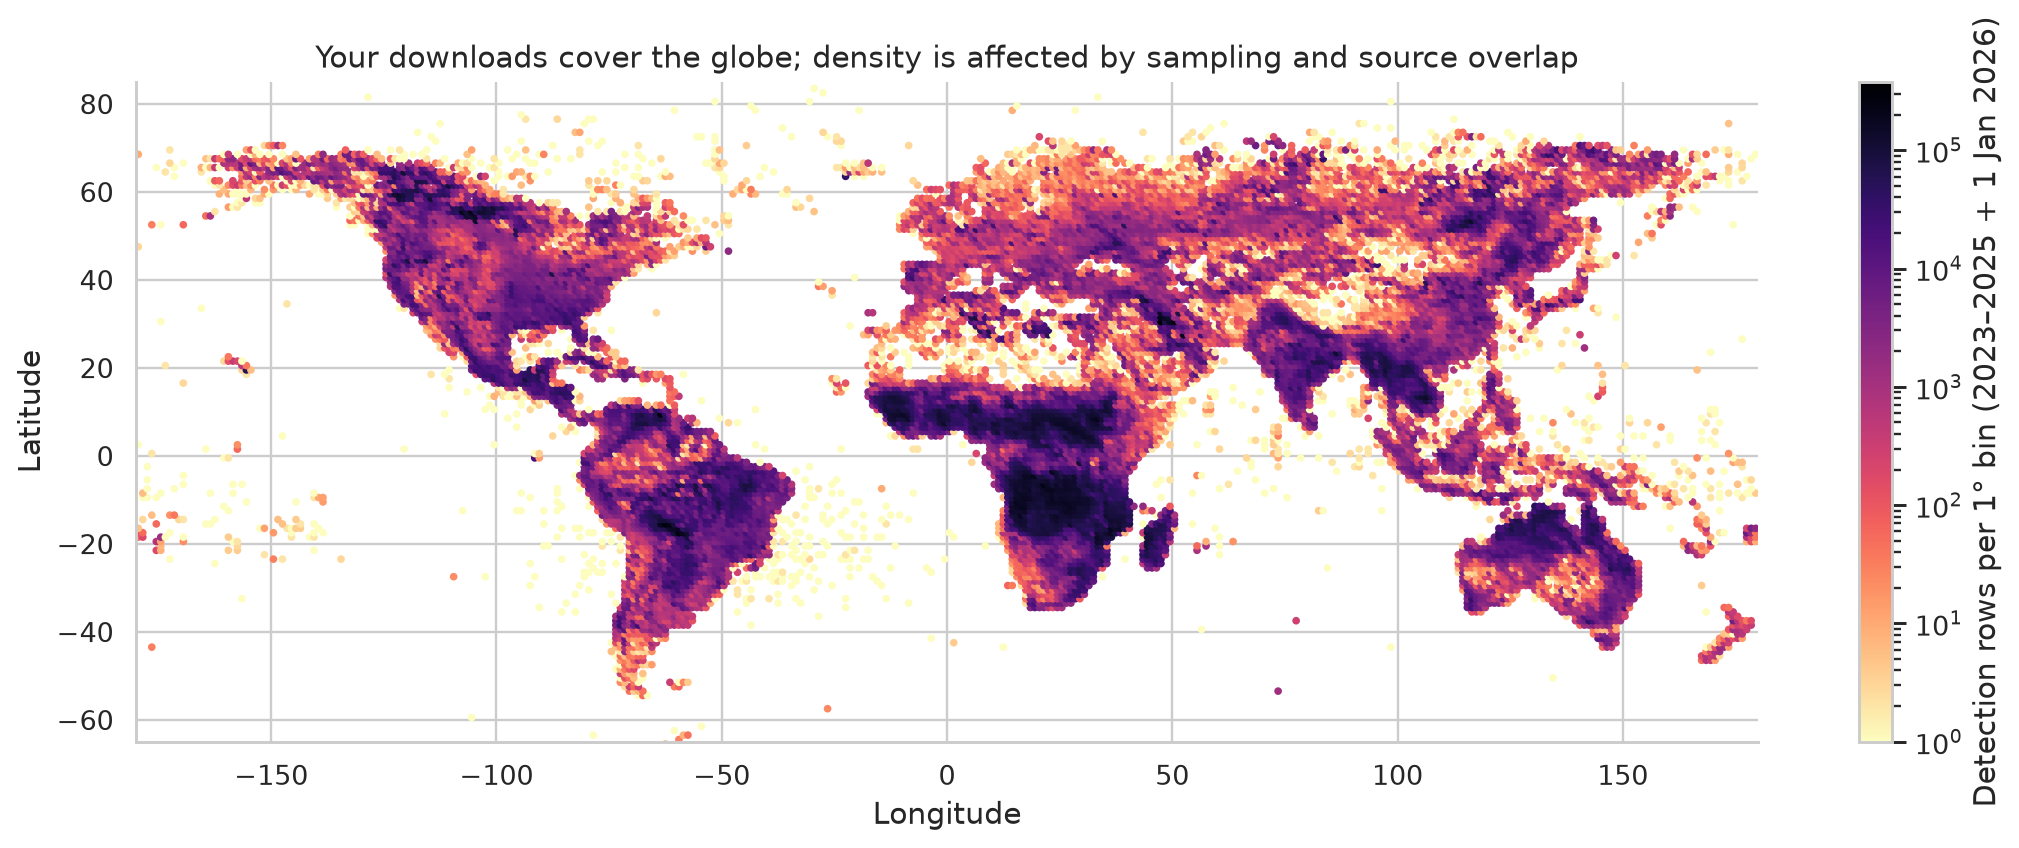

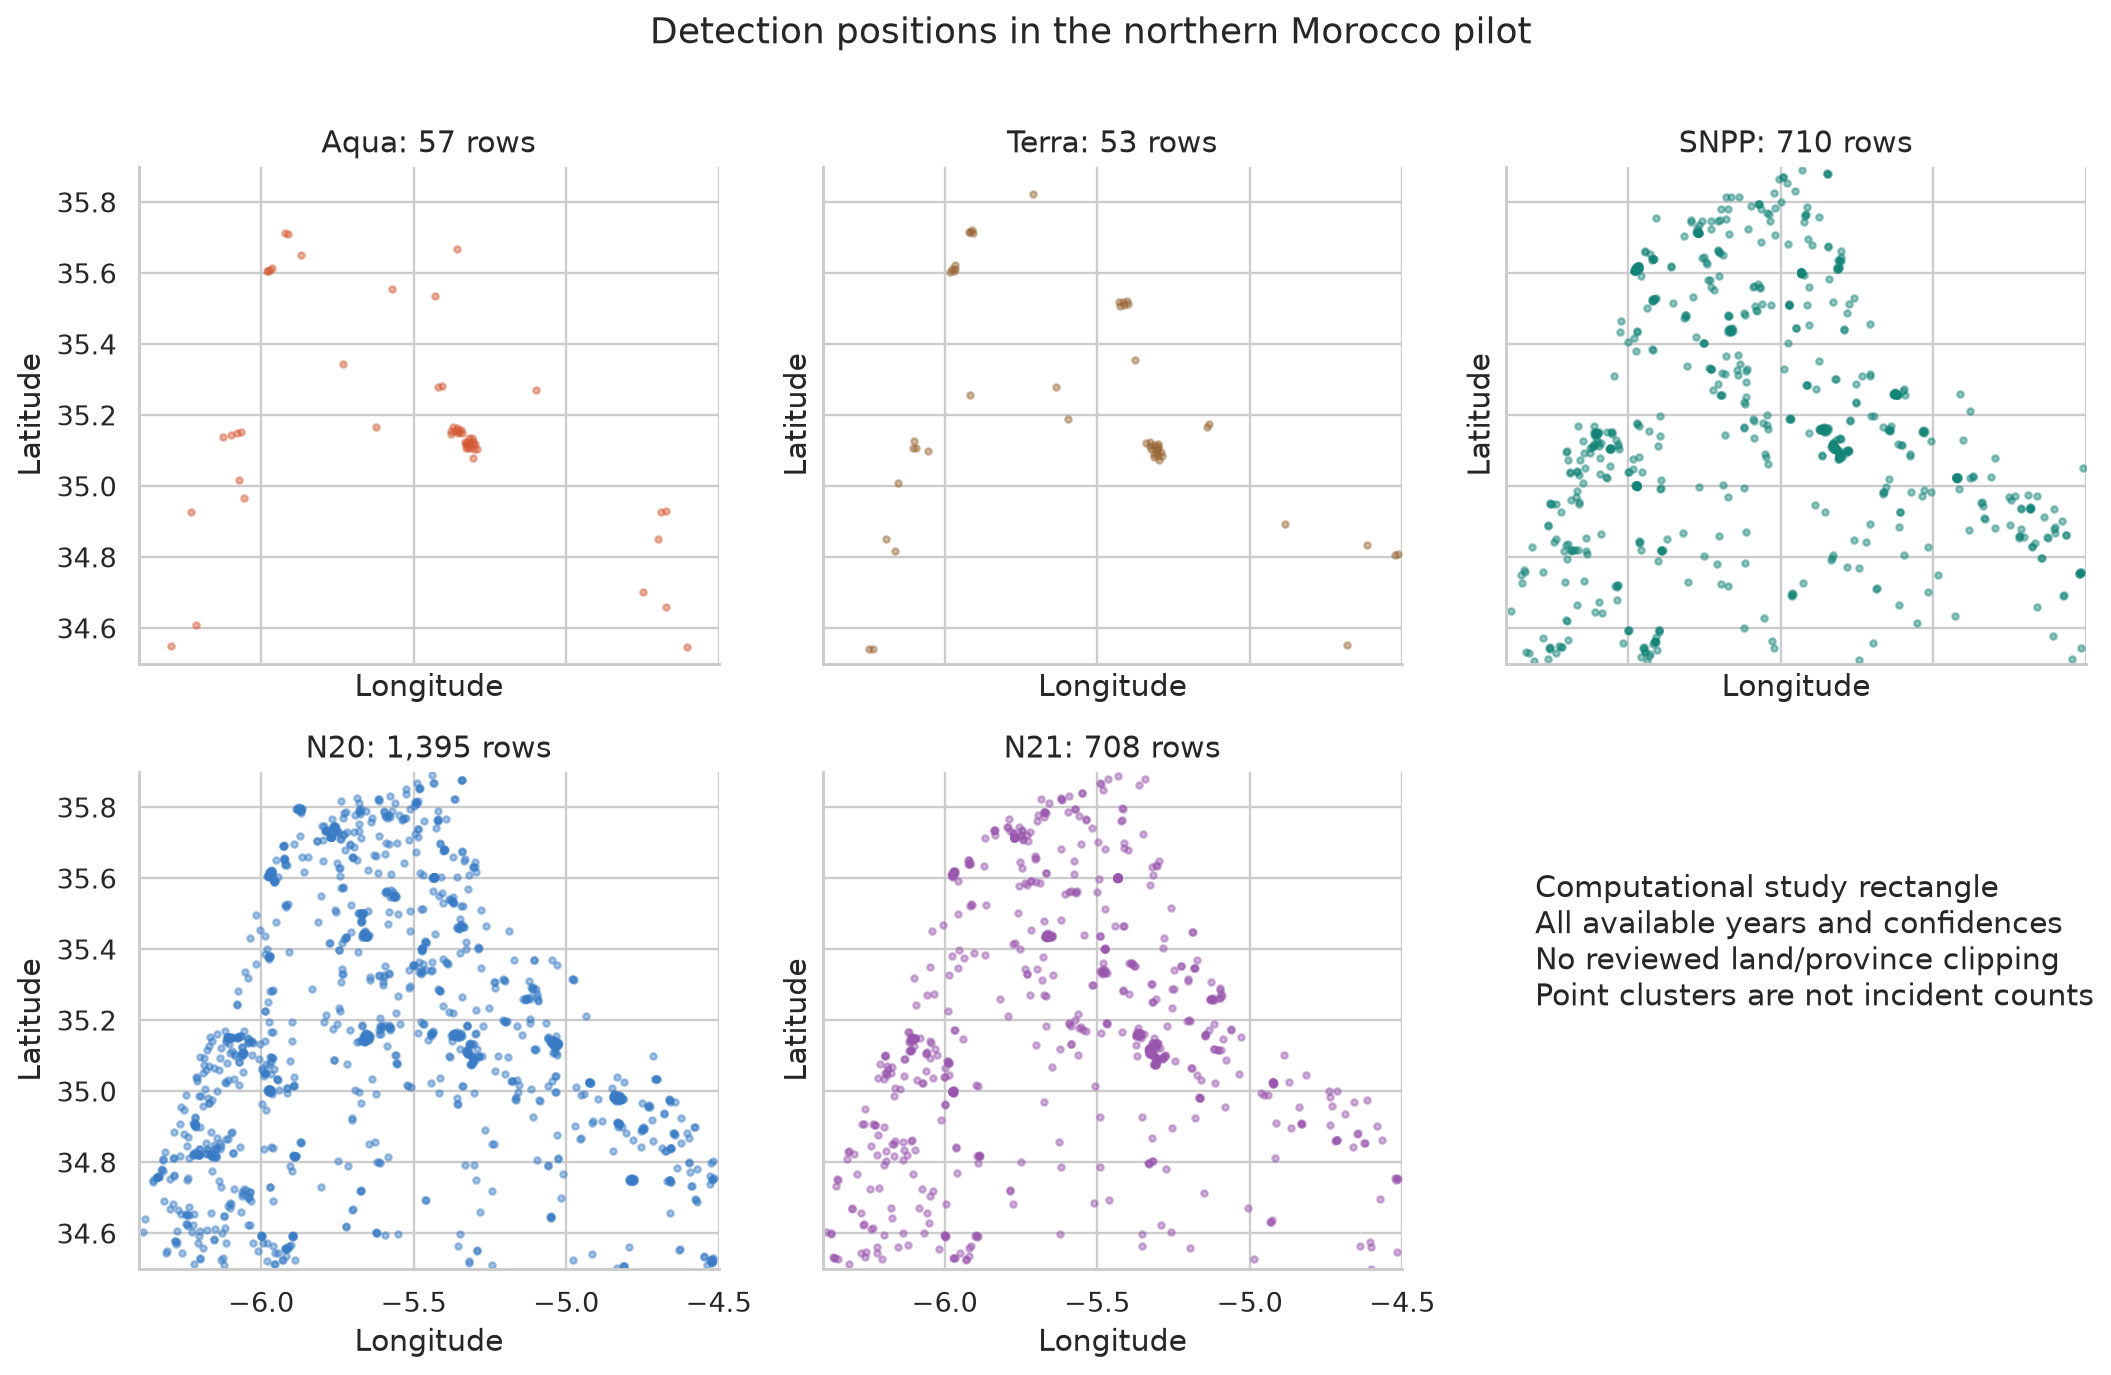

In [5]:
display(Image(filename=str(ROOT/'reports/figures/02_global_distribution.png')))
display(Image(filename=str(ROOT/'reports/figures/03_pilot_positions.png')))

In [6]:
display(regional.groupby(['satellite','stream','year'])[['pilot','southern_spain_rectangle','morocco_context_rectangle']].sum())

pilot  southern_spain_rectangle  \
satellite stream   year                                    
Aqua      standard 2025     57                       347   
N20       standard 2023    646                      1799   
                   2024    331                      2226   
                   2025    418                      2596   
                   2026      0                         0   
N21       NRT      2024    321                      2211   
                   2025    387                      2540   
                   2026      0                         0   
SNPP      standard 2024    305                      1762   
                   2025    405                      2464   
                   2026      0                         0   
Terra     standard 2025     53                       268   

                         morocco_context_rectangle  
satellite stream   year                             
Aqua      standard 2025                        110  
N20       standard 2023                       3720  
                   2024                       2593  
                   2025                       2640  
                   2026                          4  
N21       NRT      2024                       2381  
                   2025                       2472  
                   2026                          3  
SNPP      standard 2024                       2165  
                   2025                       2413  
                   2026                          6  
Terra     standard 2025                        152

## 4. Calendar, year overlap and missing observation support

Adjacent annual downloads can overlap on January 1. The regional table is exactly deduplicated before grouping by the actual UTC year. Zero exported rows does not distinguish no fire from clouds, absent passes, or download gaps. Gray calendar cells indicate months without exported global rows for that platform. Incomplete dates marks years with fewer than 365/366 distinct dates in the global export, including boundary-only years and internal gaps.

,satellite,stream,year,rows,retained,days_with_detections,median_frp_MW,max_frp_MW,median_solar_hour
0,Aqua,standard,2025,57,51,27,33.30,1350.30,14.444760
1,N20,standard,2023,646,591,182,4.38,169.86,12.370551
2,N20,standard,2024,331,305,158,2.49,56.46,12.207040
3,N20,standard,2025,418,376,156,3.35,174.95,12.337973
4,N21,NRT,2024,321,303,151,3.74,112.20,12.200833
5,N21,NRT,2025,387,348,153,4.15,265.99,12.178267
6,SNPP,standard,2024,305,288,135,2.67,86.09,12.422214
7,SNPP,standard,2025,405,364,149,2.93,278.70,12.285409
8,Terra,standard,2025,53,51,22,11.70,418.20,20.706813


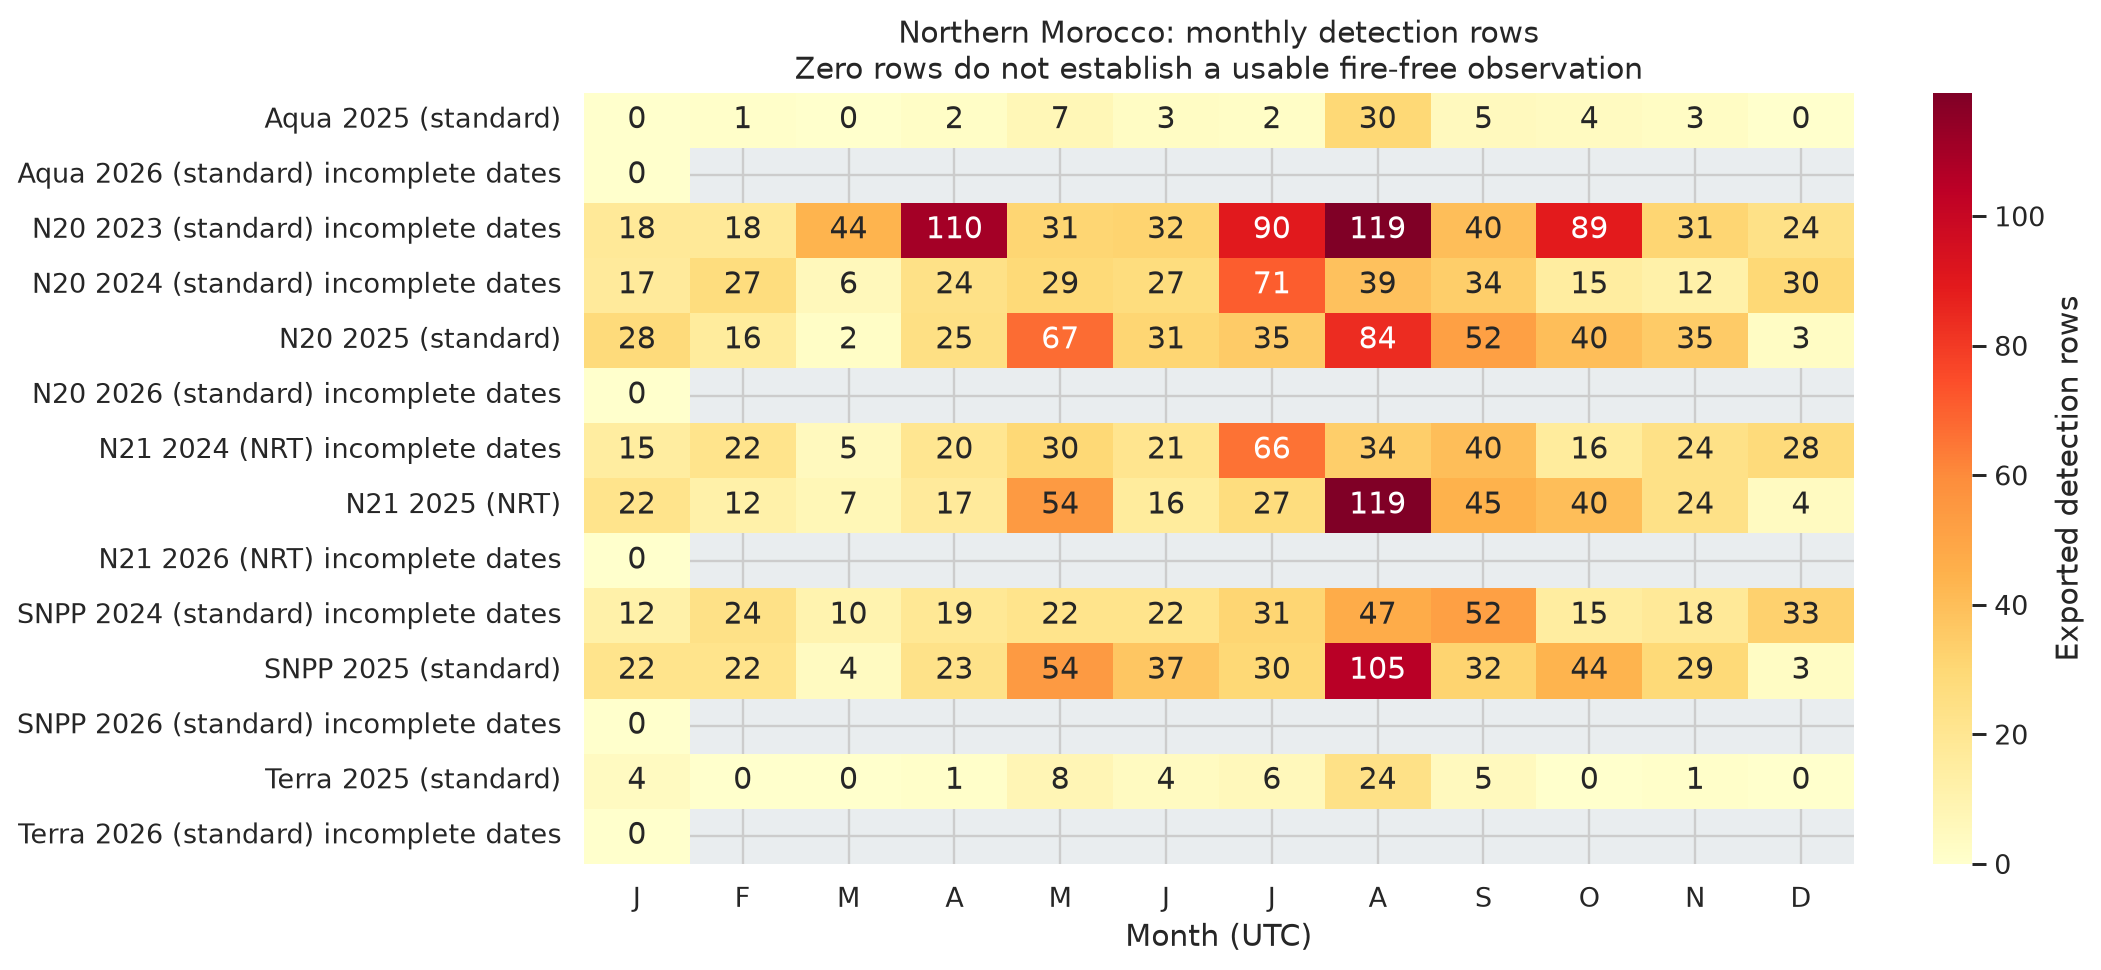

,archive,satellite,first_detection,last_detection,days_with_global_rows,days_without_global_rows_inside_file_span,dates_without_rows
0,DL_FIRE_J1V-C2_42006.zip,N20,2023-01-01,2024-01-01,361,5,"2023-07-19,2023-07-20,2023-07-21,2023-07-22,2023-09-30"
1,DL_FIRE_J1V-C2_42011.zip,N20,2024-01-01,2025-01-01,366,1,2024-02-04
2,DL_FIRE_J1V-C2_42016.zip,N20,2025-01-01,2026-01-01,366,0,NaN
3,DL_FIRE_J2V-C2_42012.zip,N21,2024-01-01,2025-01-01,358,9,"2024-02-27,2024-02-28,2024-02-29,2024-03-01,2024-03-02,2024-03-03,..."
4,DL_FIRE_J2V-C2_42017.zip,N21,2025-01-01,2026-01-01,366,0,NaN
5,DL_FIRE_LS_42010.zip,L8,2024-01-01,2025-01-01,363,4,"2024-01-21,2024-06-04,2024-06-30,2024-07-01"
6,DL_FIRE_LS_42010.zip,L9,2024-01-01,2025-01-01,362,5,"2024-01-21,2024-03-04,2024-06-04,2024-06-30,2024-07-01"
7,DL_FIRE_LS_42015.zip,L8,2025-01-01,2026-01-01,335,31,"2025-01-15,2025-09-12,2025-09-23,2025-10-14,2025-10-21,2025-10-22,..."
8,DL_FIRE_LS_42015.zip,L9,2025-01-01,2026-01-01,332,34,"2025-01-15,2025-01-16,2025-09-12,2025-09-23,2025-10-18,2025-10-19,..."
9,DL_FIRE_M-C61_42014.zip,Aqua,2025-01-01,2026-01-01,366,0,NaN


In [7]:
display(pd.read_csv(TABLES/'pilot_platform_year.csv'))
display(Image(filename=str(ROOT/'reports/figures/01_pilot_calendar.png')))
display(pd.read_csv(TABLES/'export_date_gaps.csv'))

In [8]:
# Change the platform/year to inspect a detection-only calendar.
PLATFORM = 'SNPP'
YEAR = 2025
selected = pilot[(pilot.satellite == PLATFORM) & (pilot.year == YEAR)]
counts = selected.groupby('acq_date').size()
print('Days with detections:', len(counts))
print('Observation eligibility for days without rows: UNKNOWN')
display(counts.sort_values(ascending=False).head(12).to_frame('detection_rows'))


Days with detections: 149
Observation eligibility for days without rows: UNKNOWN


,detection_rows
acq_date,
2025-08-13,46
2025-05-27,21
2025-08-22,14
2025-05-28,9
2025-01-05,9
2025-09-14,8
2025-08-12,8
2025-08-21,8
2025-07-08,7


## 5. Native confidence and thermal signal

Exploratory retained classes: MODIS confidence ≥30; VIIRS nominal/high (`n`,`h`). These are sensor-specific quality categories, not common probabilities. Compare results with and without this selection. FRP is power in MW. VIIRS thermal saturation and MODIS/VIIRS band differences affect interpretation.

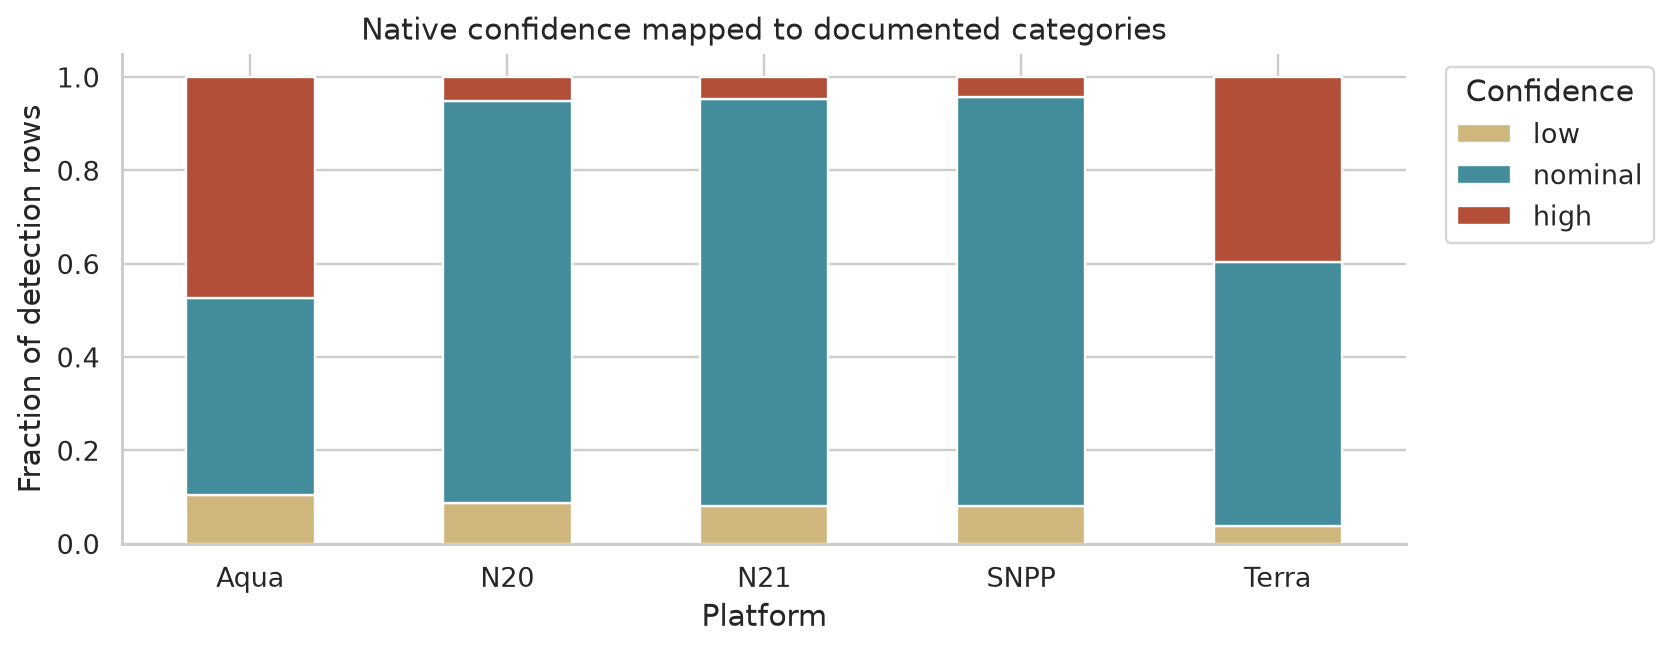

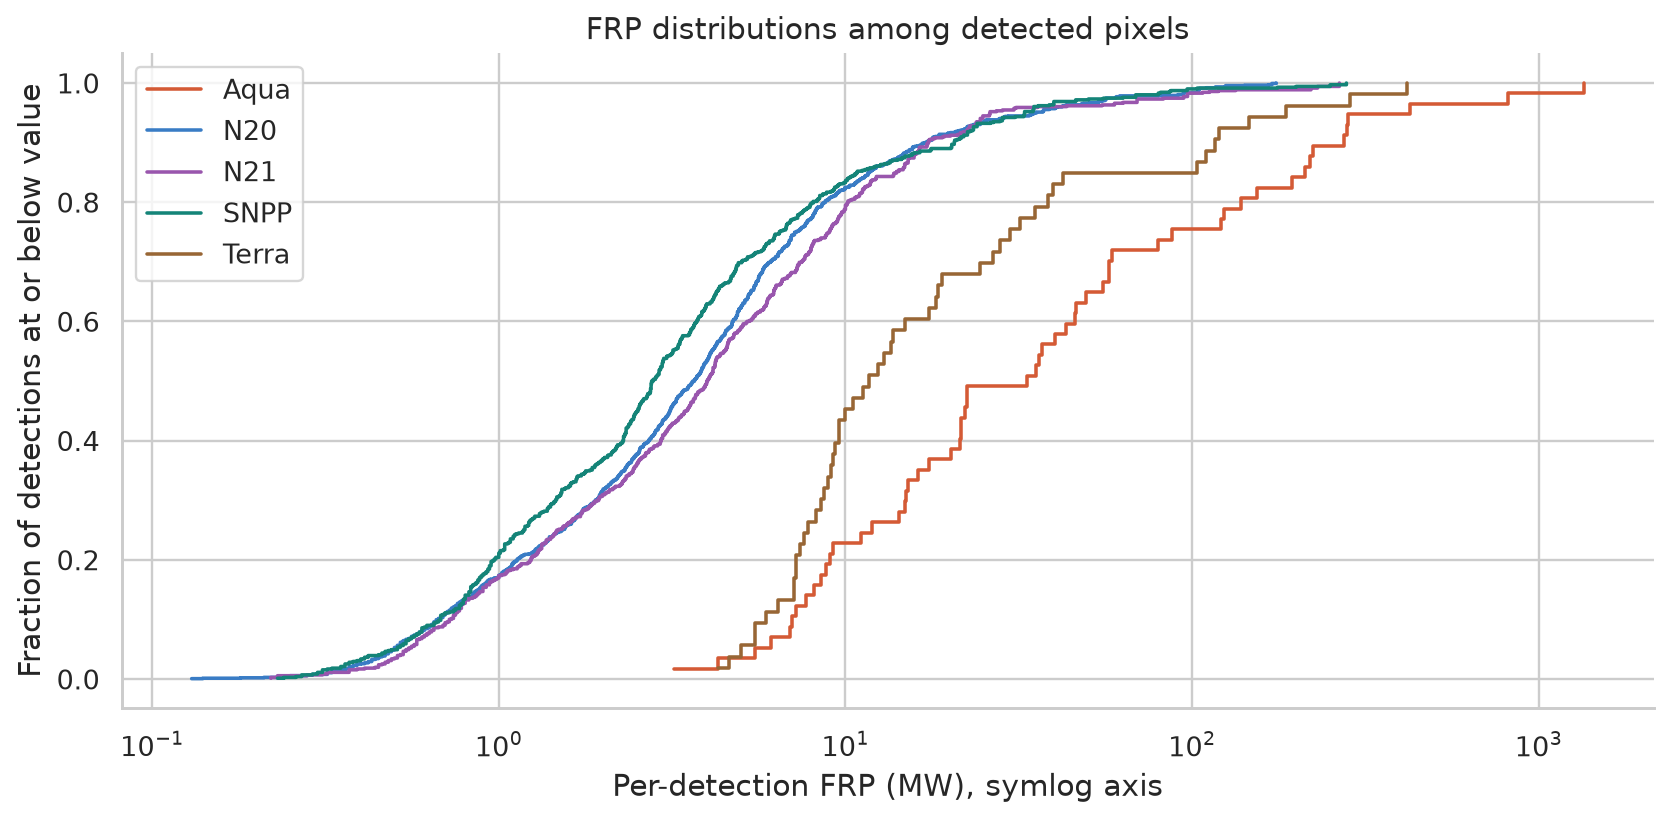

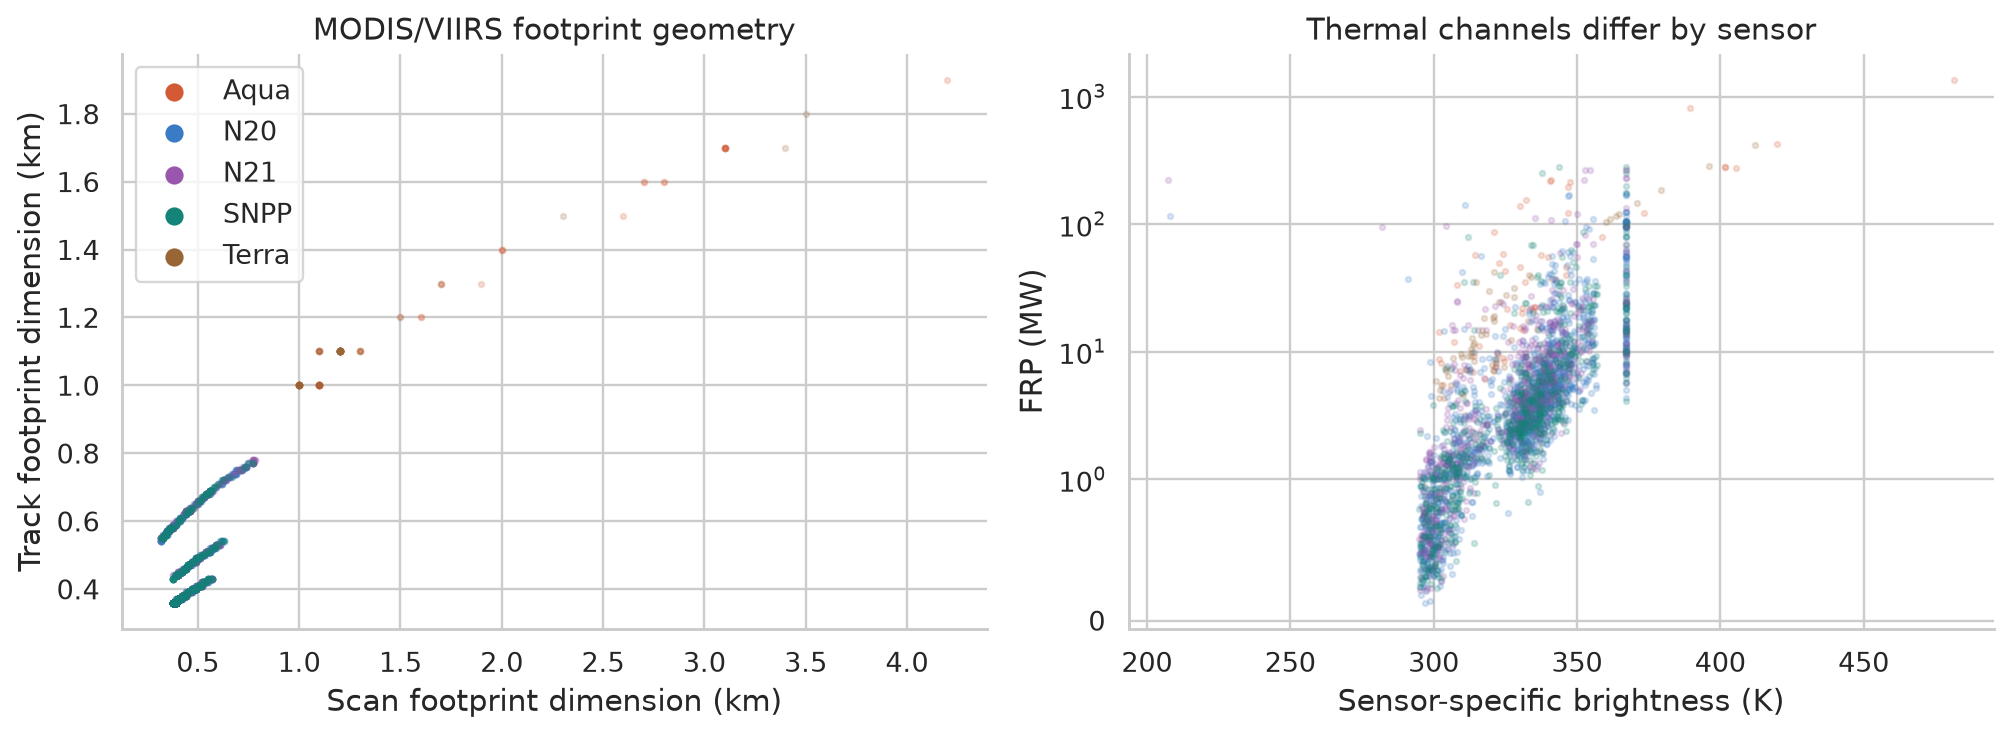

In [9]:
display(Image(filename=str(ROOT/'reports/figures/06_confidence.png')))
display(Image(filename=str(ROOT/'reports/figures/05_frp_ecdf.png')))
display(Image(filename=str(ROOT/'reports/figures/07_geometry_thermal.png')))

In [10]:
display(pilot.groupby(['satellite','stream','year']).agg(all_rows=('retained','size'),retained_rows=('retained','sum')))
display(pd.read_csv(TABLES/'pilot_type.csv'))
display(pd.read_csv(TABLES/'pilot_frp_extremes.csv').head(12))

all_rows  retained_rows
satellite stream   year                         
Aqua      standard 2025        57             51
N20       standard 2023       646            591
                   2024       331            305
                   2025       418            376
N21       NRT      2024       321            303
                   2025       387            348
SNPP      standard 2024       305            288
                   2025       405            364
Terra     standard 2025        53             51

,satellite,stream,type,rows
0,Aqua,standard,0.0,55
1,Aqua,standard,2.0,2
2,N20,standard,0.0,1379
3,N20,standard,2.0,12
4,N20,standard,3.0,4
5,N21,NRT,NaN,708
6,SNPP,standard,0.0,710
7,Terra,standard,0.0,49
8,Terra,standard,2.0,4


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,...,stream,acq_utc,sensor_family,confidence_class,retained,year,month,solar_hour,x_m,y_m,grid_x_5km,grid_y_5km,pilot,southern_spain_rectangle,morocco_context_rectangle
0,35.11570,-5.31660,481.60,1.10,1.00,2025-08-12,1455,Aqua,MODIS,100,61.03,400.10,1350.30,D,0.0,...,standard,2025-08-12 14:55:00+00:00,MODIS,high,True,2025,8,14.562227,-512978.957582,4.210810e+06,-103,842,True,False,True
1,35.15280,-5.35210,389.30,2.80,1.60,2025-08-21,1411,Aqua,MODIS,100,61.03,307.90,814.90,D,0.0,...,standard,2025-08-21 14:11:00+00:00,MODIS,high,True,2025,8,13.826527,-516404.220531,4.214698e+06,-104,842,True,False,True
2,35.11420,-5.32850,419.80,1.10,1.00,2025-08-12,1455,Aqua,MODIS,100,61.03,322.70,424.80,D,0.0,...,standard,2025-08-12 14:55:00+00:00,MODIS,high,True,2025,8,14.561433,-514127.144317,4.210652e+06,-103,842,True,False,True
3,35.11360,-5.32520,412.10,1.20,1.10,2025-08-12,2104,Terra,MODIS,100,61.03,307.60,418.20,N,0.0,...,standard,2025-08-12 21:04:00+00:00,MODIS,high,True,2025,8,20.711653,-513808.739592,4.210590e+06,-103,842,True,False,True
4,35.51020,-5.41080,395.90,1.20,1.10,2025-08-12,2104,Terra,MODIS,100,61.03,314.60,285.20,N,0.0,...,standard,2025-08-12 21:04:00+00:00,MODIS,high,True,2025,8,20.705947,-522067.965182,4.252062e+06,-105,850,True,False,True
5,35.12330,-5.33000,401.70,1.10,1.00,2025-08-12,1455,Aqua,MODIS,100,61.03,305.70,281.40,D,0.0,...,standard,2025-08-12 14:55:00+00:00,MODIS,high,True,2025,8,14.561333,-514271.873737,4.211606e+06,-103,842,True,False,True
6,35.12480,-5.31820,401.70,1.10,1.00,2025-08-12,1455,Aqua,MODIS,100,61.03,305.60,280.20,D,0.0,...,standard,2025-08-12 14:55:00+00:00,MODIS,high,True,2025,8,14.562120,-513133.335630,4.211763e+06,-103,842,True,False,True
7,35.15244,-5.35765,343.65,0.49,0.40,2025-08-21,1341,SNPP,SNPP,n,2,311.42,278.70,D,0.0,...,standard,2025-08-21 13:41:00+00:00,VIIRS,nominal,True,2025,8,13.326157,-516939.719386,4.214660e+06,-104,842,True,False,True
8,35.15615,-5.35832,367.00,0.49,0.40,2025-08-21,1341,SNPP,SNPP,l,2,380.15,278.70,D,0.0,...,standard,2025-08-21 13:41:00+00:00,VIIRS,low,False,2025,8,13.326112,-517004.365194,4.215049e+06,-104,843,True,False,True
9,35.14990,-5.34220,405.50,1.00,1.00,2025-08-22,1450,Aqua,MODIS,100,61.03,317.40,273.60,D,0.0,...,standard,2025-08-22 14:50:00+00:00,MODIS,high,True,2025,8,14.477187,-515449.006356,4.214394e+06,-104,842,True,False,True


## 6. Geometry, local time and correlation

Approximate solar time = UTC + longitude/15. Use Africa/Casablanca only for civil-time presentation. Footprint dimensions vary with viewing geometry. These distributions are conditioned on a detection; they cannot describe all usable passes.

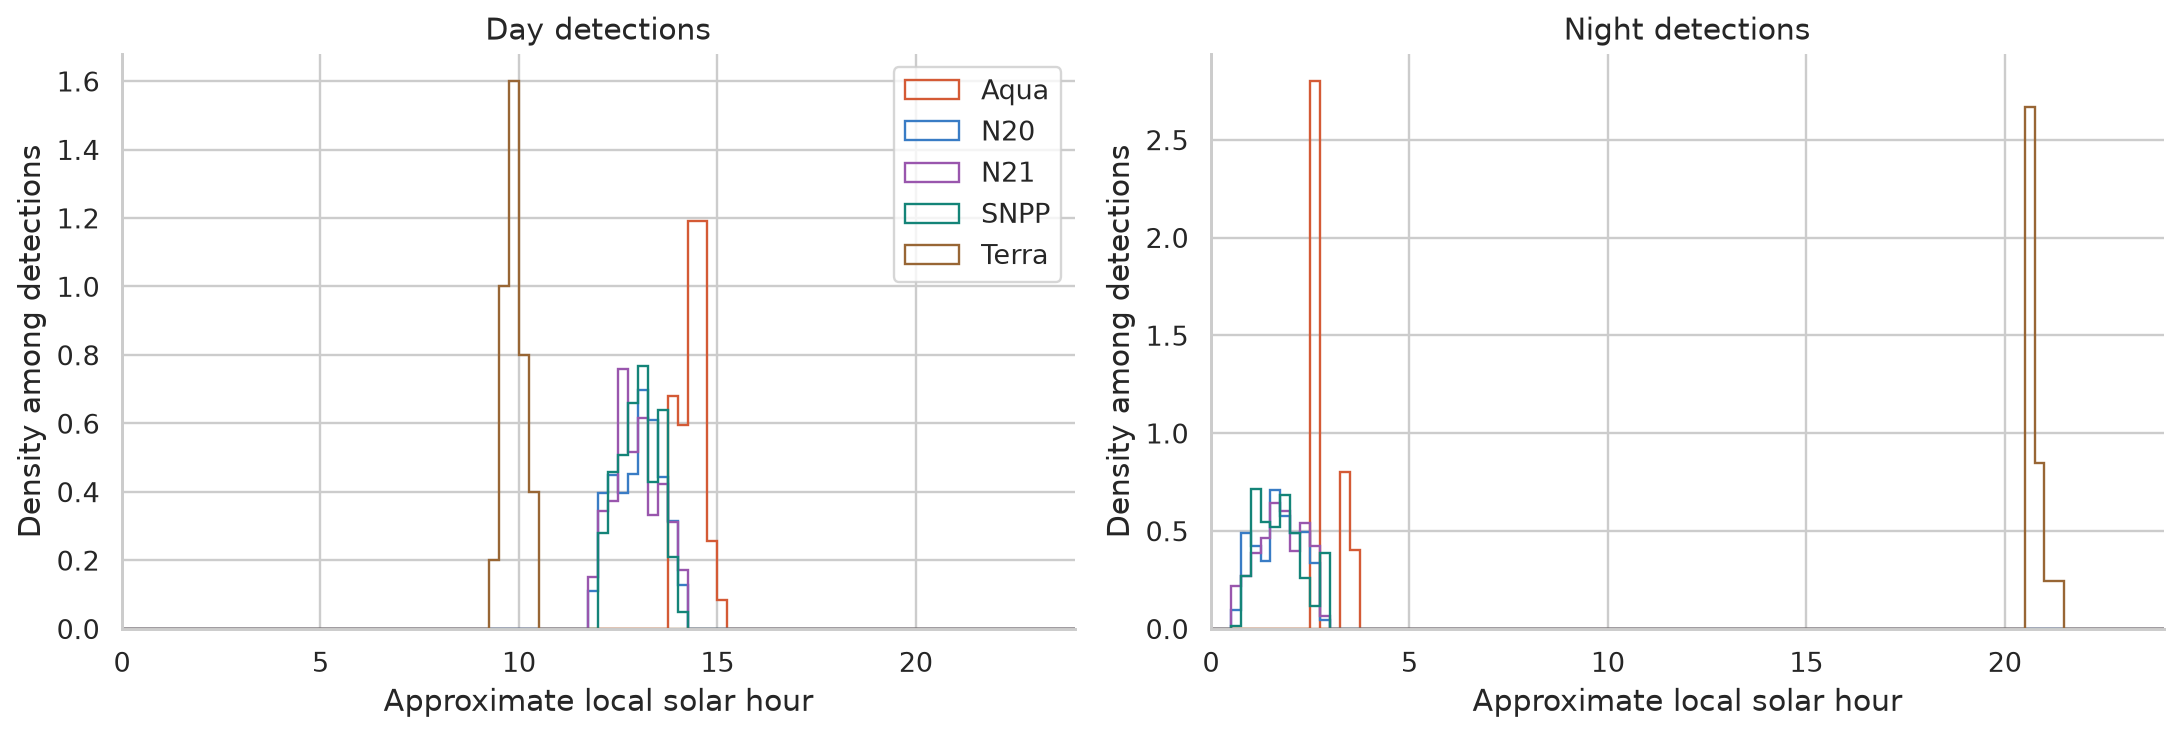

y,bright_t31,brightness,frp,scan,track
x,,,,,
bright_t31,1.000000,0.807972,0.715159,-0.065545,-0.106612
brightness,0.807972,1.000000,0.854112,-0.047381,-0.001849
frp,0.715159,0.854112,1.000000,0.083809,0.072399
scan,-0.065545,-0.047381,0.083809,1.000000,0.334265
track,-0.106612,-0.001849,0.072399,0.334265,1.000000


In [11]:
display(Image(filename=str(ROOT/'reports/figures/04_detection_times.png')))
corr = pd.read_csv(TABLES/'pilot_correlations.csv')
display(corr[corr.satellite=='SNPP'].pivot(index='x',columns='y',values='spearman_r'))

Spearman correlations are within-platform descriptive associations. They are computed as Pearson correlation of average ranks. Detector thresholds and saturation influence these relationships; do not infer causal drivers or harmonization coefficients from them.

## 7. Recurrent locations and grid sensitivity

Repeated detections in a 5 km cell warrant review but do not prove a static source. Different episodes can occur in the same cell. A positive cell-day is a deduplicated spatial/time bin; it is not an incident or an observed-fire probability.

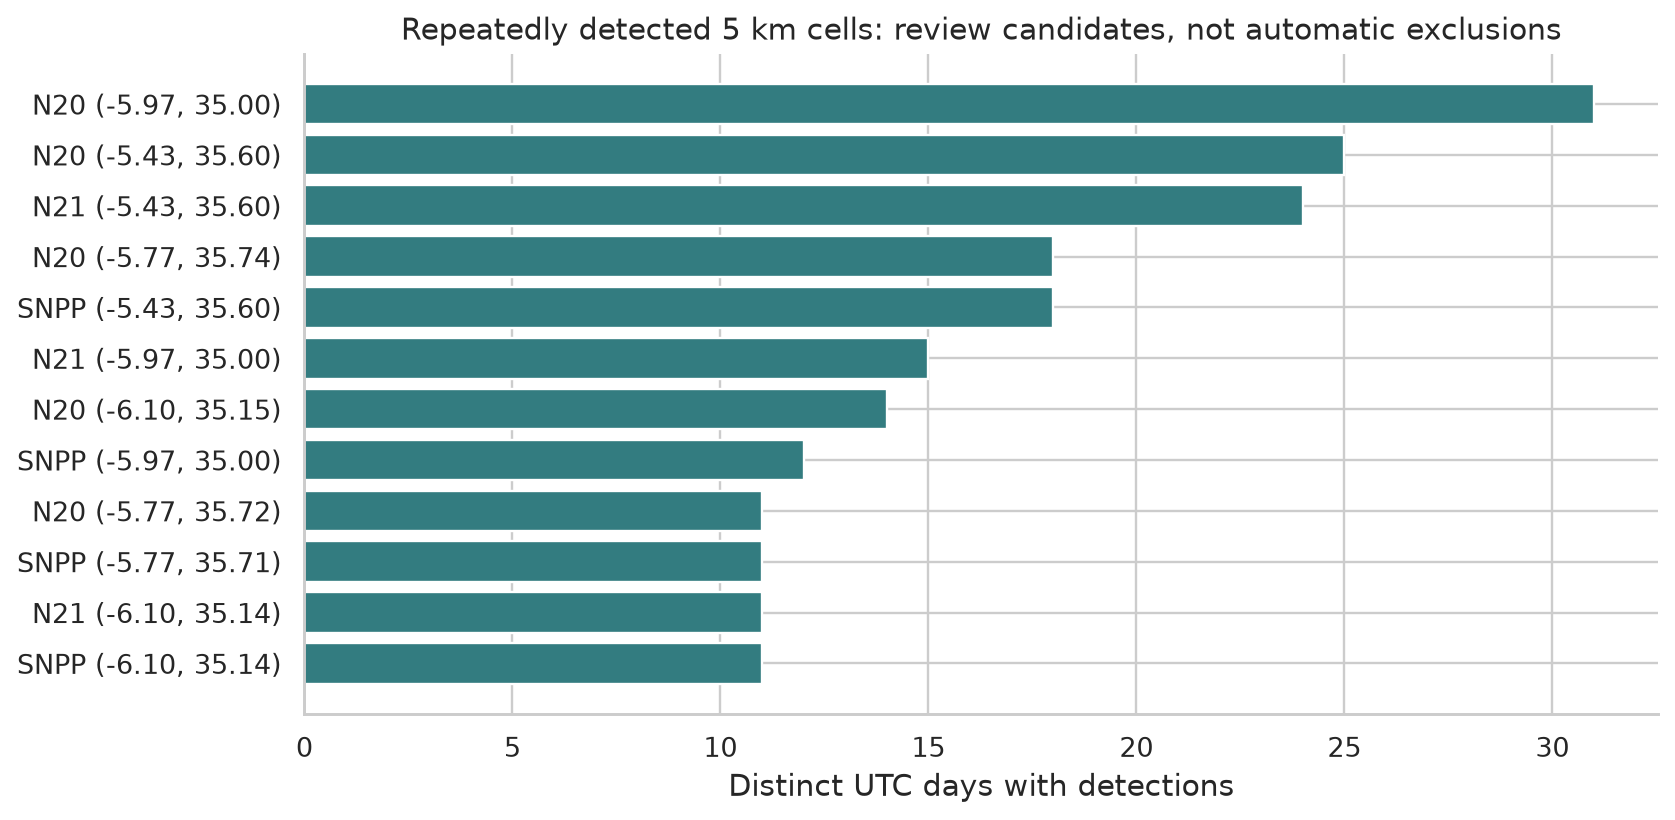

,grid_km,satellite,stream,year,detection_rows,positive_cell_days,positive_cells
0,2.0,Aqua,standard,2025,57,47,40
1,2.0,N20,standard,2023,646,376,280
2,2.0,N20,standard,2024,331,251,204
3,2.0,N20,standard,2025,418,286,237
4,2.0,N21,NRT,2024,321,245,203
5,2.0,N21,NRT,2025,387,261,208
6,2.0,SNPP,standard,2024,305,225,186
7,2.0,SNPP,standard,2025,405,261,207
8,2.0,Terra,standard,2025,53,40,35
9,5.0,Aqua,standard,2025,57,32,26


In [12]:
display(Image(filename=str(ROOT/'reports/figures/09_recurrence.png')))
display(pd.read_csv(TABLES/'grid_sensitivity.csv'))

## 8. Positive-only matching diagnostic

The diagnostic pairs both-positive acquisition timestamp groups in the same equal-area grid cell, separately for each source/reference series. It uses actual time gaps with no reuse and restricts candidates to the supplied Aqua year (2025). This is **not** the blueprint's matched-opportunity table: fire masks, full geolocation, usable-area intersection and valid negatives are absent.

,grid_km,tolerance_min,source,pairs,source_positive_times,aqua_positive_times,median_gap_min
0,2.0,15,SNPP,0,129,34,NaN
1,2.0,15,N20,2,150,34,5.5
2,2.0,30,SNPP,4,129,34,30.0
3,2.0,30,N20,2,150,34,5.5
4,2.0,60,SNPP,6,129,34,30.0
5,2.0,60,N20,4,150,34,22.0
6,5.0,15,SNPP,1,118,27,9.0
7,5.0,15,N20,3,134,27,7.0
8,5.0,30,SNPP,4,118,27,24.0
9,5.0,30,N20,3,134,27,7.0


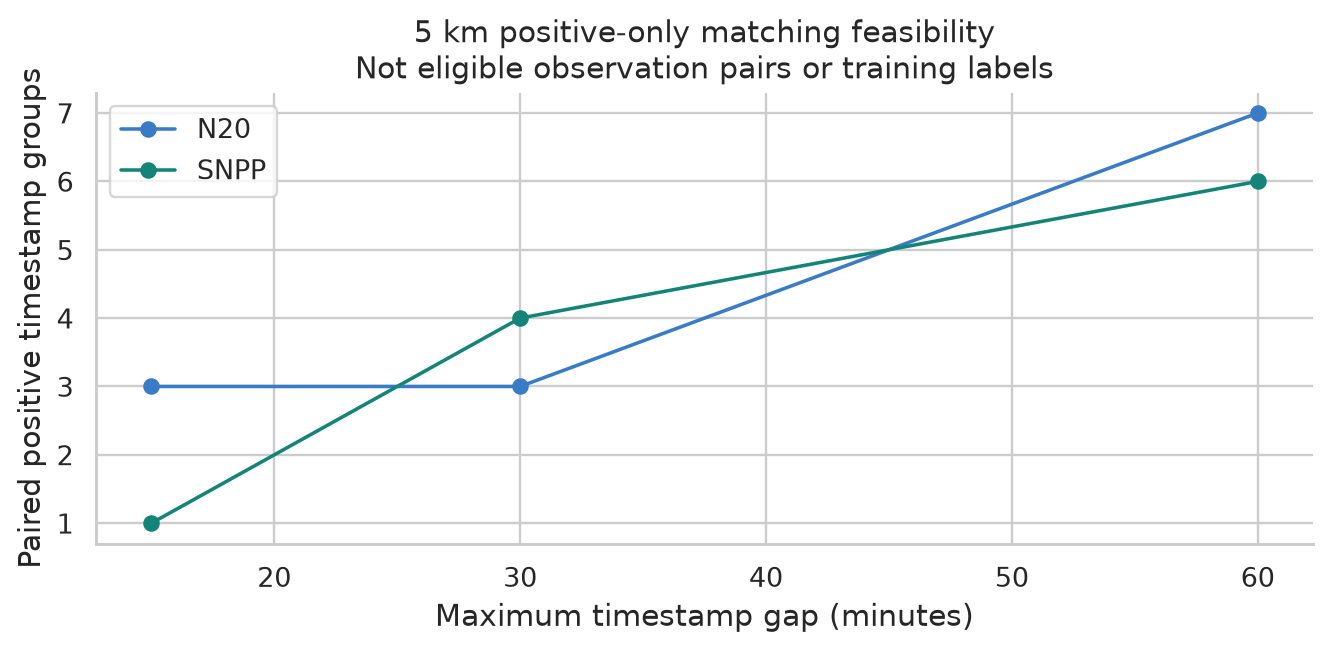

In [13]:
display(pd.read_csv(TABLES/'positive_timestamp_pair_diagnostics.csv'))
display(Image(filename=str(ROOT/'reports/figures/08_pairing_feasibility.png')))

## 9. Added dataset: EFFIS national context

The downloaded workbook contains reported country-level annual burned area and forest-fire counts. Blanks stay missing. These measurements differ from FIRMS hotspot rows and cover entire countries, whereas the pilot covers a small rectangle. They provide historical context, not pixel-level validation labels. Source: [EFFIS data and services](https://forest-fire.emergency.copernicus.eu/applications/data-and-services).

,country,year,burnt_area_ha,reported_forest_fires
40,ESP,2020,65923.00,7745.0
41,ESP,2021,87880.00,8780.0
42,ESP,2022,267947.00,10507.0
43,ESP,2023,89068.00,7748.0
44,ESP,2024,47711.13,6134.0
85,MAR,2020,5569.00,514.0
86,MAR,2021,3064.00,435.0
87,MAR,2022,22762.00,499.0
88,MAR,2023,6246.00,466.0
89,MAR,2024,874.00,382.0


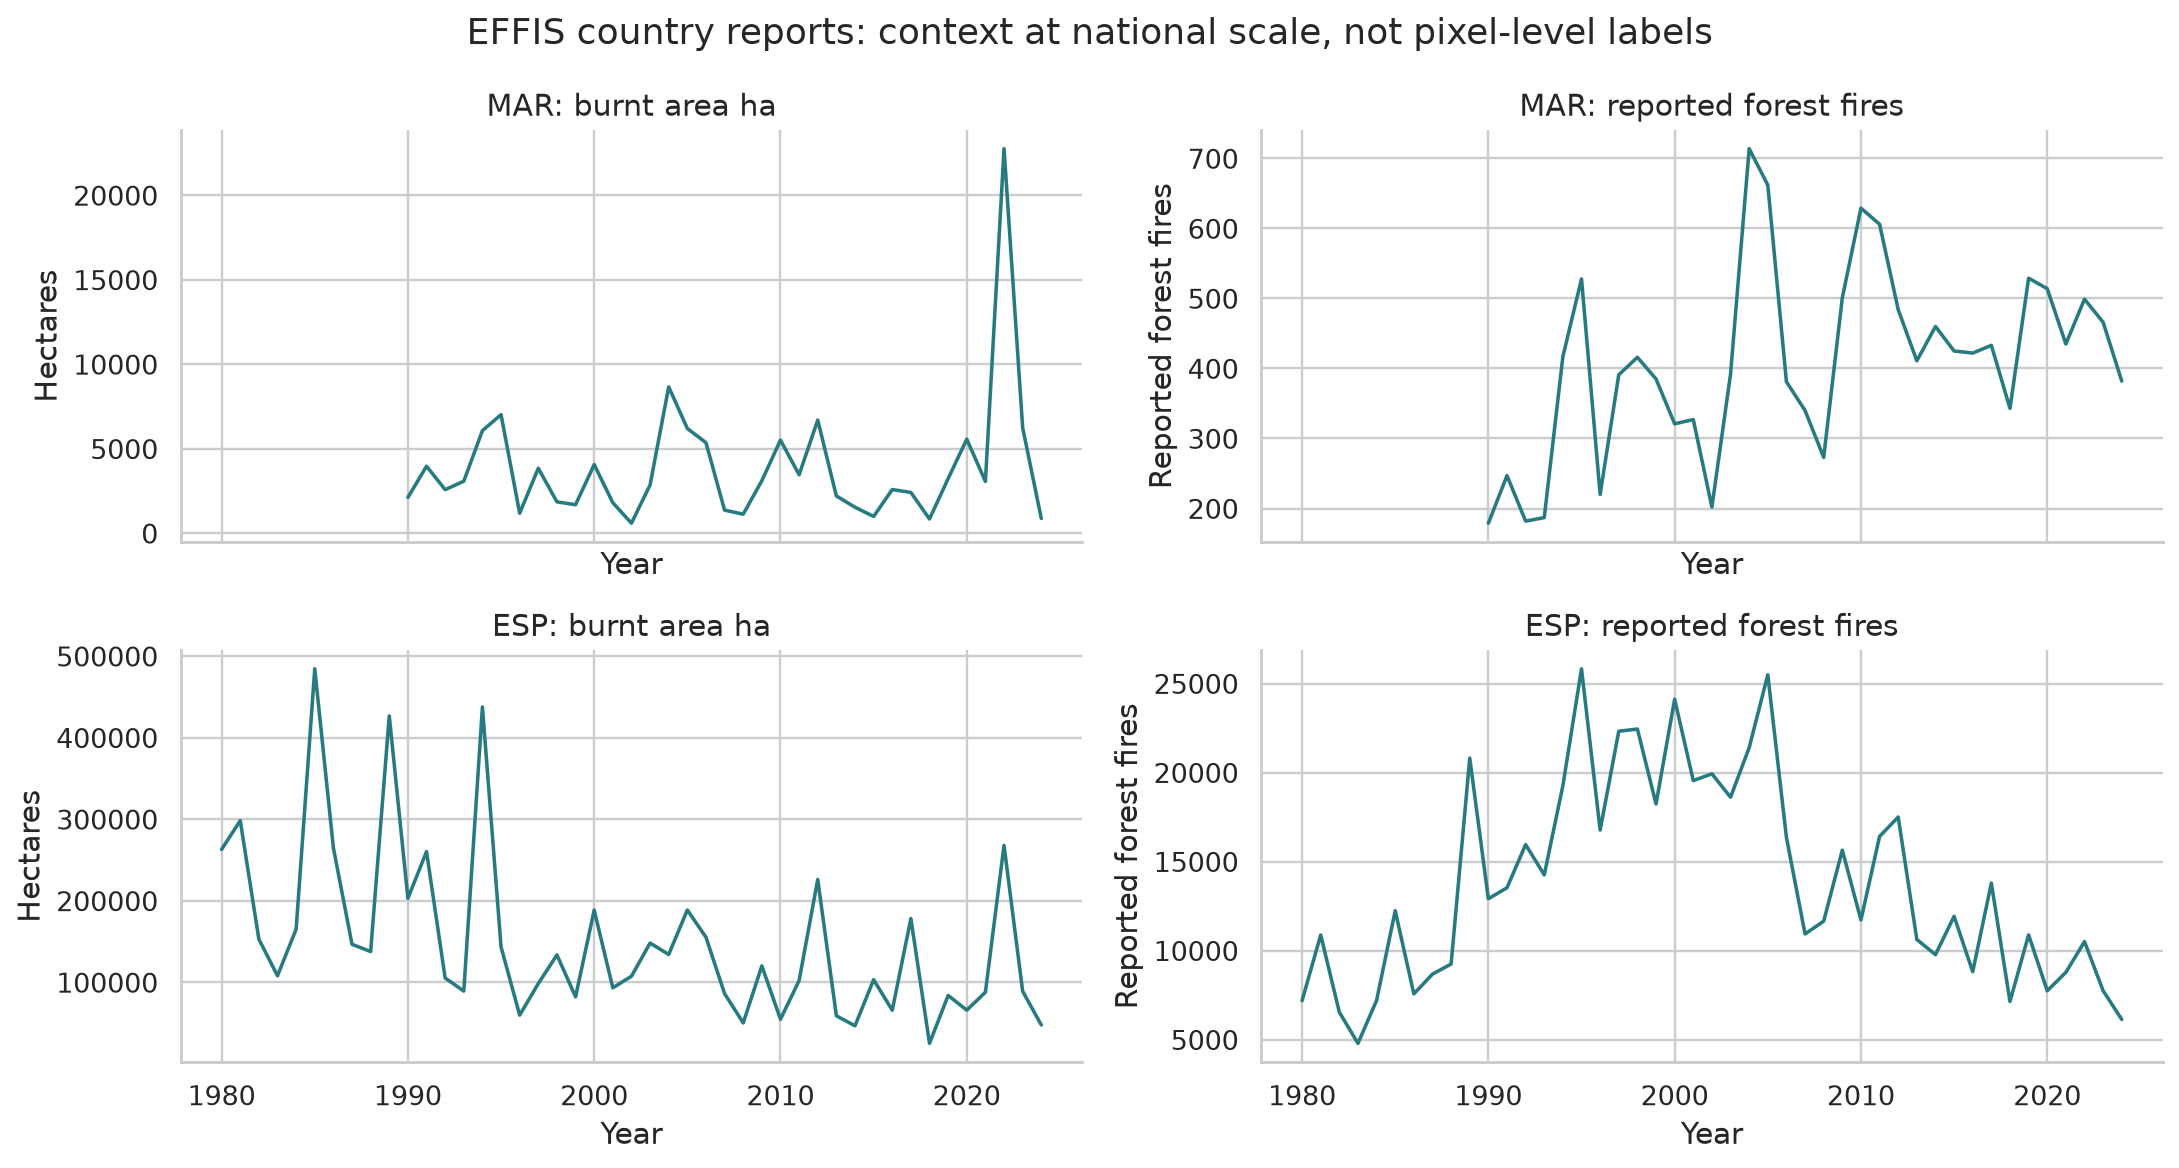

In [14]:
effis = pd.read_csv(TABLES/'effis_morocco_spain.csv')
display(effis[effis.year >= 2020])
display(Image(filename=str(ROOT/'reports/figures/10_effis_context.png')))

## 10. Additional science files and access status

A one-week granule catalog is saved for July 14–20, 2025. A bounded smoke-test plan selects one near-time daytime Aqua/S-NPP quartet and two context tiles. Discovery and download are distinct statuses. No credentials appear in the notebook.

In [15]:
manifest = json.loads((TABLES/'science_download_manifest.json').read_text())
display(pd.DataFrame(manifest)[['product','filename','size_MB_catalog','status']])
display(pd.DataFrame(json.loads((TABLES/'download_manifest.json').read_text()))[['name','kind','status','bytes']])

,product,filename,size_MB_catalog,status
0,MCD12Q1,MCD12Q1.A2024001.h17v05.061.2025205145403.hdf,8.720057,requires_Earthdata_token
1,MCD64A1,MCD64A1.A2025182.h17v05.061.2025258144905.hdf,1.096880,requires_Earthdata_token
2,MYD14,MYD14.A2025200.1405.061.2025201111254.hdf,0.368158,requires_Earthdata_token
3,VNP14IMG,VNP14IMG.A2025200.1400.002.2025205122531.nc,1.794582,requires_Earthdata_token
4,MYD03,MYD03.A2025200.1405.061.2025201145900.hdf,33.570030,requires_Earthdata_token
5,VNP03IMG,VNP03IMG.A2025200.1400.002.2025200232341.nc,155.646821,requires_Earthdata_token


,name,kind,status,bytes
0,cmr_VNP14IMG_collections.json,metadata,downloaded,7126.0
1,cmr_MYD14_collections.json,metadata,downloaded,16185.0
2,cmr_MYD03_collections.json,metadata,downloaded,17138.0
3,cmr_MYD14_C2278858993-LPCLOUD_granules.json,metadata,downloaded,79618.0
4,cmr_VNP03IMG_collections.json,metadata,downloaded,3719.0
5,cmr_MYD03_C1379841358-LAADS_granules.json,metadata,downloaded,43708.0
6,cmr_VJ114IMG_collections.json,metadata,downloaded,6250.0
7,cmr_VNP03IMG_C2105092163-LAADS_granules.json,metadata,downloaded,57913.0
8,cmr_VJ103IMG_collections.json,metadata,downloaded,3882.0
9,cmr_VJ103IMG_C2105086226-LAADS_granules.json,metadata,downloaded,71553.0


In [16]:
science_profile = TABLES/'science_profiles.json'
if science_profile.exists():
    display(pd.DataFrame(json.loads(science_profile.read_text())))
else:
    print('Science-file decoding awaits authenticated downloads; local point EDA is complete.')

Science-file decoding awaits authenticated downloads; local point EDA is complete.


## 11. What to do next

1. Acquire paired fire masks and compatible geolocation across contiguous periods including non-detection days.
2. Verify QA codes, shapes, fill values, scale factors, spatial footprints and companion acquisition keys.
3. Compute shared usable land support on a reviewed grid/AOI before creating negatives.
4. Acquire the missing historical years and freeze time/geography splits before model selection.
5. Compare simple aggregation and logistic calibration before more complex models.

The current EDA supports source-specific descriptive analysis. The comparable activity metric and coverage denominator remain unavailable until observation eligibility is established.